# 04 Improvements (Track B)
Tuning, ensembles and analysis. All numbers are on UNSEEN days (leave-one-day-out) unless stated. Produced by `run_tuning.py`, `run_tuning_b.py`, `run_tuning_b2.py`, `run_ensemble.py` and `run_analysis.py`.

In [1]:
import pandas as pd
from pathlib import Path
from IPython.display import Image, display
R = Path('..') / 'results'
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

## 1. Hyperparameter tuning (Optuna, nested leave-one-day-out)
Default settings vs tuned settings. A negative improvement means tuning made the unseen-day error worse.

In [2]:
t = pd.read_csv(R / 'tuning' / 'optuna_leaderboard.csv')
t[['model','subject','default_lodo_mse','tuned_nested_mse','improvement_pct','spearman_day']].round(4)

,model,subject,default_lodo_mse,tuned_nested_mse,improvement_pct,spearman_day
0,"NN (1 hidden, paper-style)",S1,0.0158,0.0182,-14.9704,0.5866
1,"NN (1 hidden, paper-style)",S2,0.0358,0.0375,-4.7806,0.3333
2,MLP (1-3 layers),S1,0.0153,0.0177,-15.6733,0.5847
3,MLP (1-3 layers),S2,0.0383,0.0674,-75.9848,0.3198
4,Random Forest,S1,0.0577,0.0504,12.5858,0.4547
5,Random Forest,S2,0.0278,0.0275,0.8429,0.3261
6,Extra Trees,S1,0.0336,0.0363,-8.1523,0.5324
7,Extra Trees,S2,0.0273,0.0309,-13.2165,0.2449
8,Gradient Boosting,S1,0.0480,0.0423,11.8494,0.3912
9,Gradient Boosting,S2,0.0333,0.0246,26.1351,0.3100


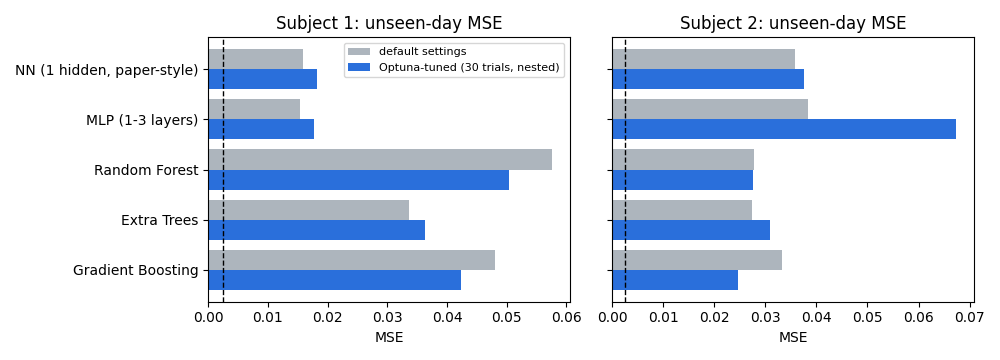

In [3]:
display(Image(str(R / 'figures' / 'e3_optuna_tuning.png')))

### Our seed-averaged network, tuned the same way

In [4]:
pd.read_csv(R / 'track_b' / 'b6_tuned_nn.csv').round(4)

,experiment,model,subject,feature_set,default_lodo_mse,tuned_nested_mse,improvement_pct,n_trials,seconds,tuned_r2,tuned_skill,tuned_spearman_day,tuned_top5_in_top10
0,b6,paper_nn_tuned,S1,all,0.0186,0.0180,2.8056,30,207,0.7257,0.8033,0.5674,0.52
1,b6,paper_nn_tuned,S1,step+emg,0.0215,0.0215,-0.1497,30,199,0.6723,0.7650,0.6224,0.72
2,b6,paper_nn_tuned,S2,all,0.0311,0.0345,-10.9636,30,339,0.0369,0.2796,0.2978,0.32
3,b6,paper_nn_tuned,S2,step+emg,0.0474,0.0765,-61.3967,30,257,-1.1366,-0.5982,0.1695,0.44


### Fixing 'tuning made Subject 2 worse': smaller search space and averaging the best 5 settings

In [5]:
pd.read_csv(R / 'track_b' / 'b6b_tuned_nn_robust.csv').round(4)

,experiment,subject,feature_set,default_lodo_mse,n_trials,wide_mse,wide_vs_default_pct,small_mse,small_vs_default_pct,small_top5_mse,small_top5_vs_default_pct,seconds
0,b6b,S1,all,0.0186,20,0.0181,2.5368,0.0188,-1.3995,0.0193,-4.1296,248
1,b6b,S1,step+emg,0.0215,20,0.0196,8.7259,0.0240,-11.3375,0.0229,-6.5983,237
2,b6b,S2,all,0.0311,20,0.0282,9.1605,0.0339,-9.2383,0.0348,-11.9756,277
3,b6b,S2,step+emg,0.0474,20,0.0677,-42.8194,0.0539,-13.7721,0.0483,-2.0493,237


## 2. Ensembles vs their members

In [6]:
e = pd.read_csv(R / 'track_b' / 'b5_ensemble.csv')
e[e.feature_set=='all'].pivot_table(index=['subject','protocol'], columns='model', values='mse').round(4)

model                 gp   ridge  stacking     svr  voting_all  voting_smooth
subject protocol                                                             
S1      kfold     0.0079  0.0089    0.0112  0.0108      0.0084         0.0082
        lodo      0.0249  0.0143    0.0216  0.0418      0.0248         0.0180
S2      kfold     0.0126  0.0164    0.0169  0.0146      0.0112         0.0129
        lodo      0.0356  0.0357    0.0279  0.0591      0.0312         0.0326

## 3. Which features matter (permutation importance on unseen days)

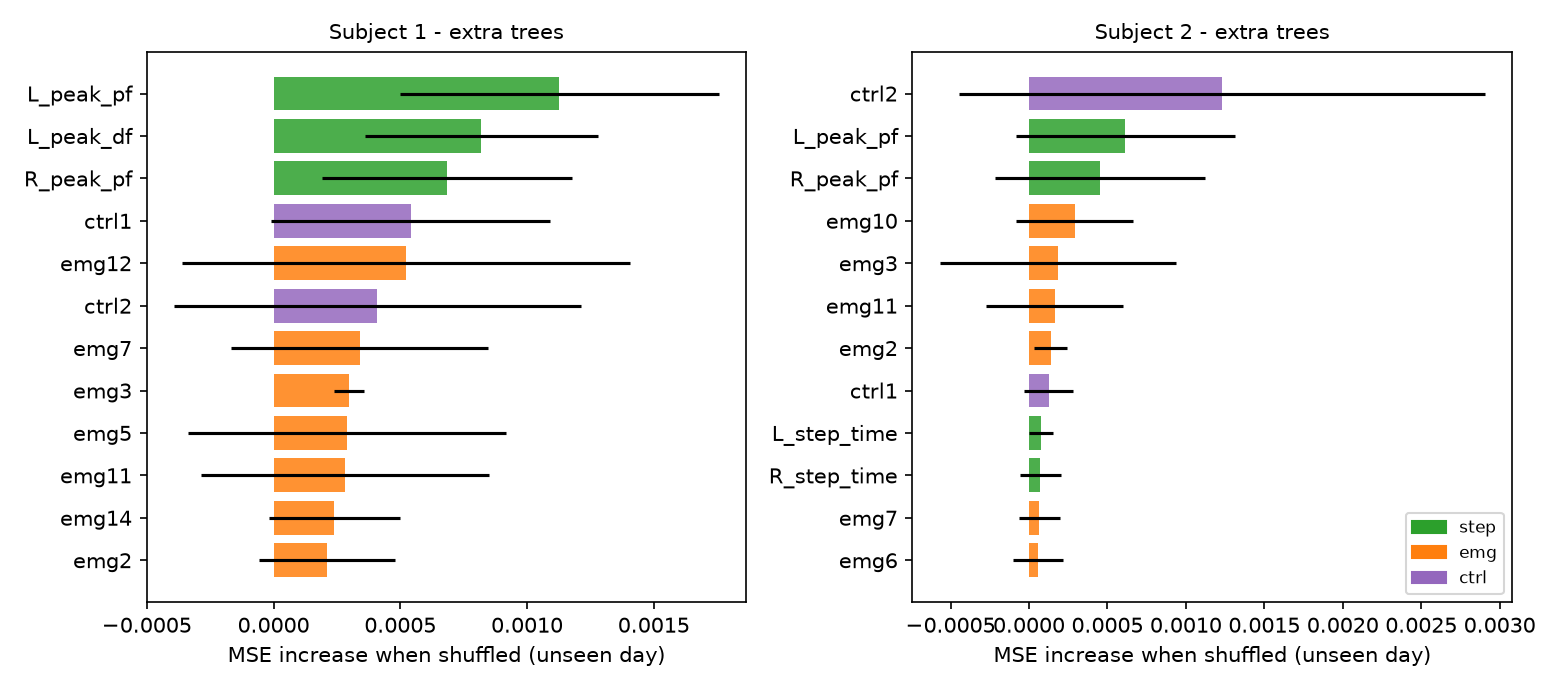

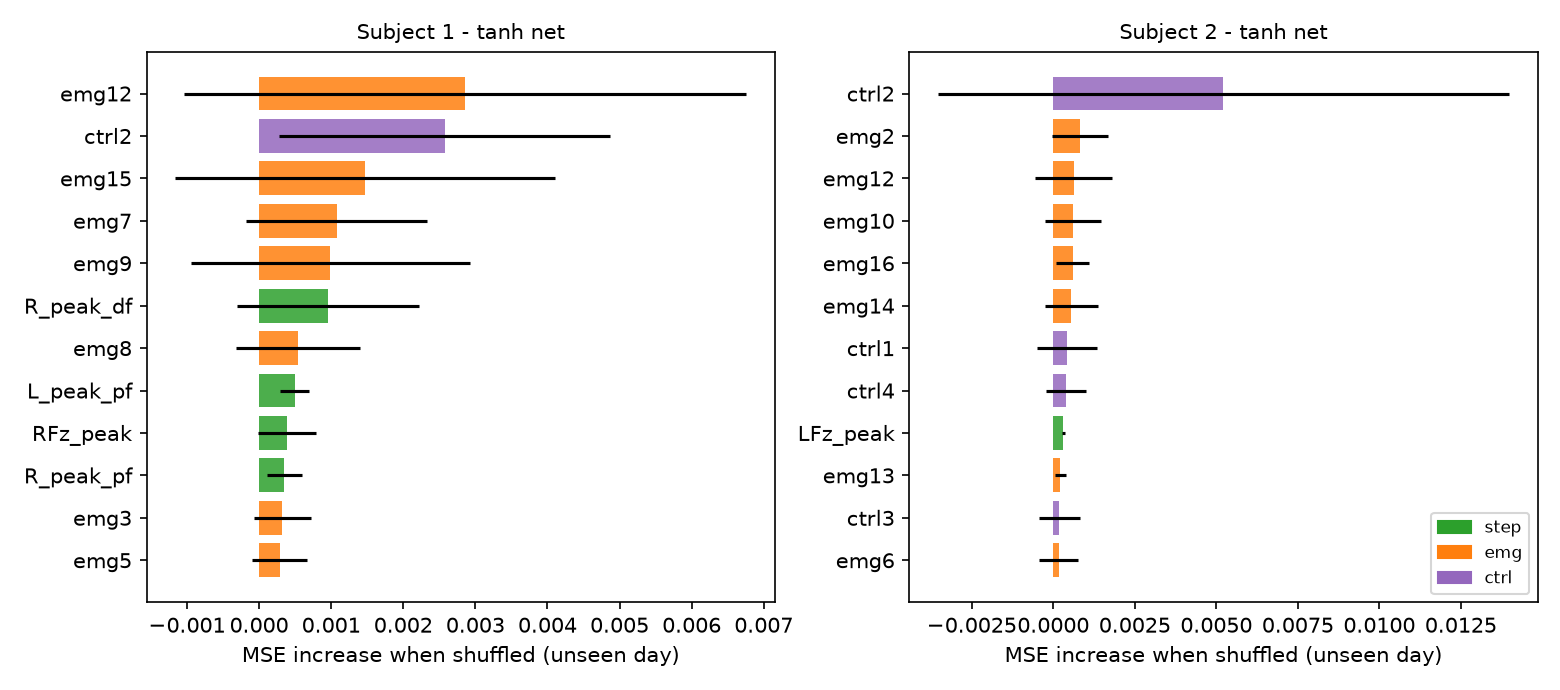

In [7]:
display(Image(str(R / 'figures' / 'b7_perm_importance_et.png')))
display(Image(str(R / 'figures' / 'b7_perm_importance_nn.png')))

## 4. Learning curves (error vs number of training days)

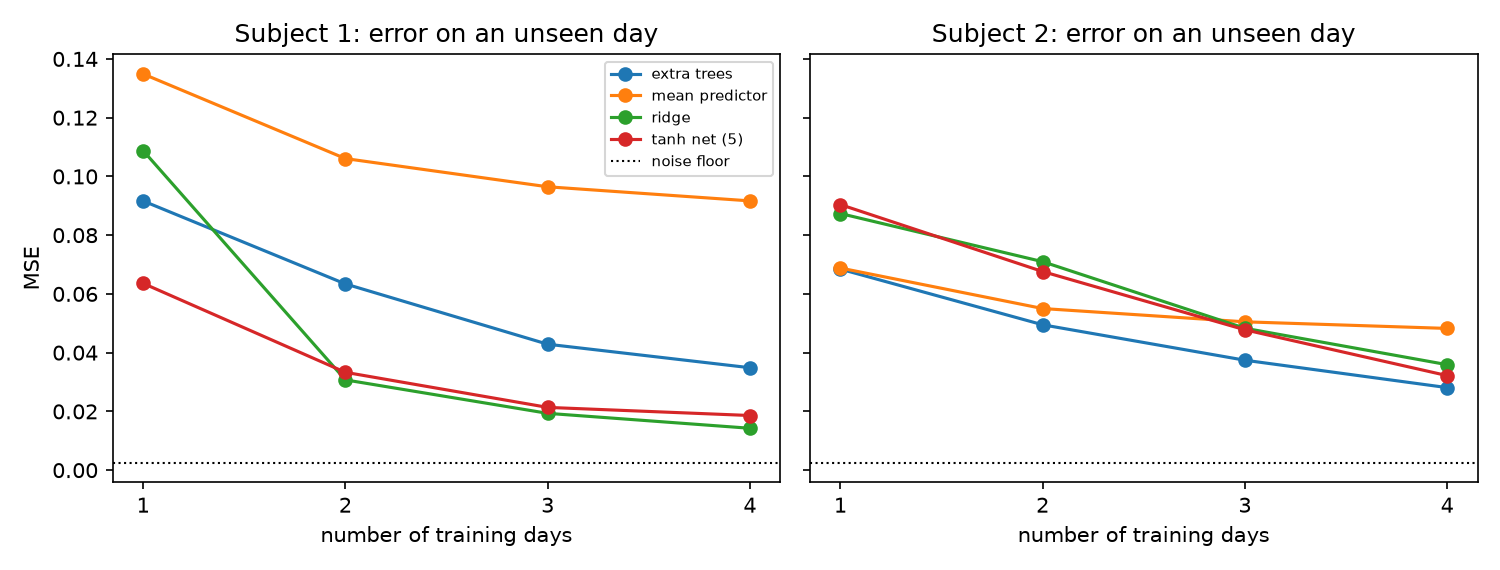

In [8]:
display(Image(str(R / 'figures' / 'b7_learning_curve.png')))

## 5. Error on each held-out day

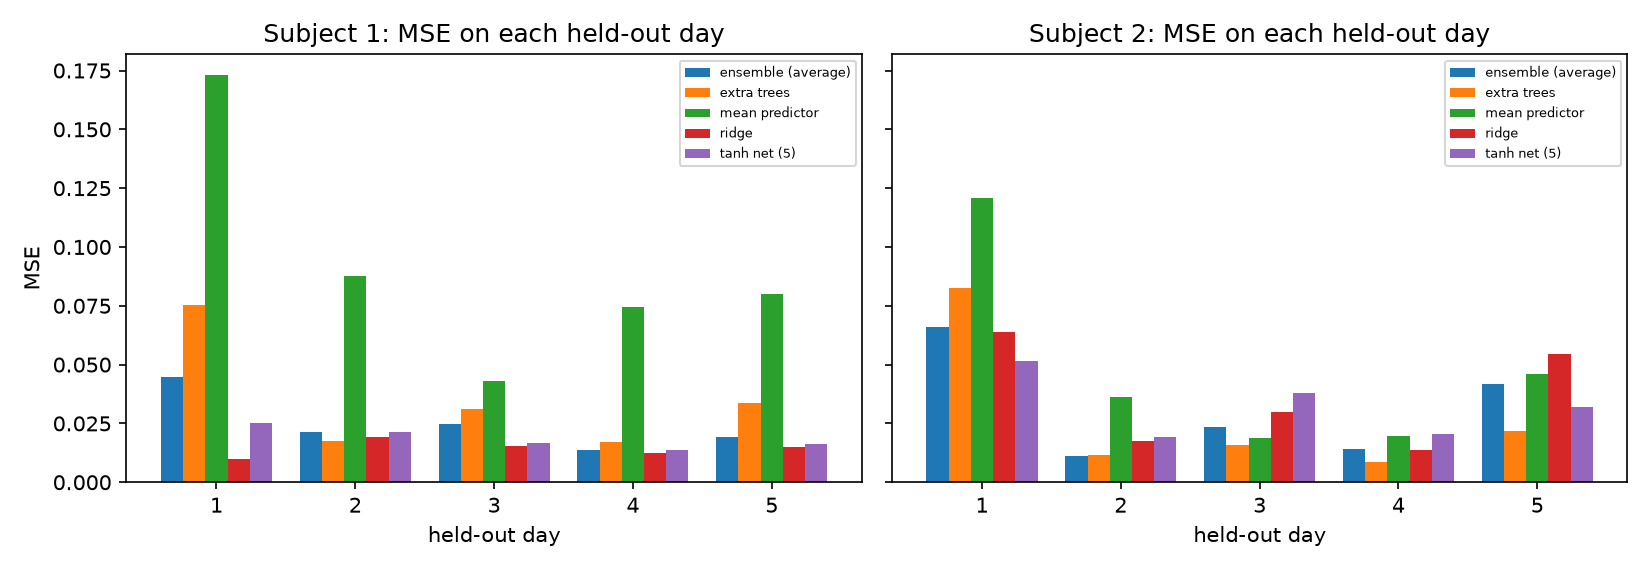

In [9]:
display(Image(str(R / 'figures' / 'b7_per_day_mse.png')))

## 6. How close are we to the noise floor?

In [10]:
pd.read_csv(R / 'track_b' / 'b7_noise_floor_table.csv').round(4)

,subject,protocol,model,feature_set,mse,noise_floor,times_noise_floor
0,S1,kfold,gp,all,0.0079,0.0025,3.2
1,S1,lodo,ridge,all,0.0143,0.0025,5.7
2,S2,kfold,extended_mlp,step+emg,0.0097,0.0025,3.9
3,S2,lodo,gradient_boosting,all,0.0251,0.0025,10.1
